
# 02 — Baseline, contact point e primo fit Hertz-like

Questo notebook parte dagli output già generati dal reader:

```text
afm_output/
├── csv_curves/
├── summary_segment0_with_qc.csv
└── plots_overview/
```

Obiettivo: prendere le curve già convertite in CSV, stimare baseline e contact point, costruire una indentazione relativa e fare un primo fit meccanico:

\[
F(\delta) = A\,\delta^{3/2}
\]

Per ora `A` è un **parametro elastico efficace**, non ancora il modulo di Young assoluto. Per convertirlo in \(E\) servono geometria della punta, raggio e coefficiente di Poisson.


In [1]:

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

warnings.filterwarnings("ignore")

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "afm_output"
CSV_DIR = OUTPUT_DIR / "csv_curves"
SUMMARY_PATH = OUTPUT_DIR / "summary_segment0_with_qc.csv"

FIT_OUTPUT_DIR = OUTPUT_DIR / "fit_hertz_like"
FIT_PLOTS_DIR = FIT_OUTPUT_DIR / "plots"
FIT_TABLE_PATH = FIT_OUTPUT_DIR / "fit_results_segment0.csv"

FIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIT_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", PROJECT_DIR)
print("CSV_DIR exists:", CSV_DIR.exists(), CSV_DIR)
print("SUMMARY exists:", SUMMARY_PATH.exists(), SUMMARY_PATH)


Working directory: /Users/gmoretti/Work/AFM/Code_General
CSV_DIR exists: True /Users/gmoretti/Work/AFM/Code_General/afm_output/csv_curves
SUMMARY exists: True /Users/gmoretti/Work/AFM/Code_General/afm_output/summary_segment0_with_qc.csv



## 1. Caricamento del summary

Il summary contiene una riga per curva. Lo useremo per sapere quali curve esistono, a quale gruppo appartengono e quali erano state eventualmente flaggate nel controllo qualità preliminare.


In [2]:

summary = pd.read_csv(SUMMARY_PATH)
print("Numero righe summary:", len(summary))
display(summary.head())

print("\nColonne disponibili:")
print(list(summary.columns))


Numero righe summary: 257


,status,file,file_name,group,segment_id,segment_style,segment_name,n_points,z_min_um,z_max_um,...,cantilever_id,tip_radius,tip_half_angle,time_stamp,force_corr_max_nN_robust_z,baseline_noise_pN_robust_z,z_range_um_robust_z,n_points_robust_z,qc_score,qc_flag_simple
0,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.409008,-9.411679,...,2300FE,NaN,NaN,2026-02-25 09\:09\:43.503 +0100,0.086722,1.260798,1.417023,NaN,1.417023,False
1,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,4700,-15.592912,-10.896858,...,2300FE,NaN,NaN,2026-02-25 09\:11\:47.886 +0100,1.022848,0.564639,-545.355224,NaN,545.355224,True
2,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,5413,-15.767386,-10.357957,...,2300FE,NaN,NaN,2026-02-25 09\:11\:49.808 +0100,-0.283640,4.543361,-245.608188,NaN,245.608188,True
3,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0007.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.621139,-9.624797,...,2300FE,NaN,NaN,2026-02-25 09\:11\:51.934 +0100,-0.442651,0.387903,1.002005,NaN,1.002005,False
4,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0008.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.645828,-9.651365,...,2300FE,NaN,NaN,2026-02-25 09\:11\:54.151 +0100,1.600985,0.946572,0.212477,NaN,1.600985,False



Colonne disponibili:
['status', 'file', 'file_name', 'group', 'segment_id', 'segment_style', 'segment_name', 'n_points', 'z_min_um', 'z_max_um', 'z_range_um', 'force_min_nN', 'force_max_nN', 'force_corr_max_nN', 'force_corr_min_nN', 'baseline_nN', 'baseline_noise_pN', 'spring_N_per_m', 'sensitivity_m_per_V', 'cantilever_name', 'cantilever_id', 'tip_radius', 'tip_half_angle', 'time_stamp', 'force_corr_max_nN_robust_z', 'baseline_noise_pN_robust_z', 'z_range_um_robust_z', 'n_points_robust_z', 'qc_score', 'qc_flag_simple']


## 2. Trova i CSV delle curve

Il notebook cerca automaticamente i CSV del segmento 0, cioè quello che stiamo trattando come approach/extend.

Nota importante: il notebook 01 salva i CSV in sottocartelle per gruppo. Per questo qui usiamo `CSV_DIR.rglob("*.csv")`, cioè una ricerca ricorsiva.


In [3]:
# Cerca ricorsivamente: i CSV del notebook 01 sono dentro sottocartelle per gruppo.
all_csv = sorted(CSV_DIR.rglob("*.csv"))
print("CSV trovati:", len(all_csv))
print("Primi 20 CSV:")
for p in all_csv[:20]:
    print(" -", p.relative_to(CSV_DIR))

# Segmento 0 = extend/approach. Pattern robusto sui nomi tipo cito-0007_segment0.csv.
seg0_csv = [
    p for p in all_csv
    if (
        "segment0" in p.name.lower()
        or "segment_0" in p.name.lower()
        or "seg0" in p.name.lower()
        or "seg_0" in p.name.lower()
    )
]

# Fallback: se il nome non contiene segment0, prova a leggere meta_segment_id.
if len(seg0_csv) == 0 and len(all_csv) > 0:
    print("\nNon trovo segment0 nel nome. Provo a leggere meta_segment_id dentro i CSV...")
    candidate = []
    for p in all_csv:
        try:
            tmp = pd.read_csv(p, nrows=1)
            if "meta_segment_id" in tmp.columns and int(tmp["meta_segment_id"].iloc[0]) == 0:
                candidate.append(p)
        except Exception:
            pass
    seg0_csv = candidate

print("\nCSV segmento 0 selezionati:", len(seg0_csv))

if len(seg0_csv) == 0:
    raise RuntimeError(
        "Non ho trovato CSV del segmento 0. "
        "Controlla che il notebook 01 abbia esportato i CSV e che siano in afm_output/csv_curves/."
    )


CSV trovati: 514
Primi 20 CSV:
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment1.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0005_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0005_segment1.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0006_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0006_segment1.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0007_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0007_segment1.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0008_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0008_segment1.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0009_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0009_segment1.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0011_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0011_segment1.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0012_segment0.csv
 - Petri20k_MCF7R_t48h_cito_20260225/cito-0012_segment1.csv
 - Petri2


## 3. Funzioni: pulizia, contact point e fit

La logica è volutamente semplice e robusta:

1. prende `z_tip_um` e `force_nN`;
2. sottrae la baseline stimata sulla parte iniziale della curva;
3. liscia leggermente la forza per stimare il punto di contatto;
4. trova il primo punto in cui la forza supera una soglia basata sul rumore;
5. definisce l'indentazione relativa come distanza dal contact point;
6. fitta la regione post-contatto con \(F = A \delta^{3/2}\).

Questa è una prima versione. Non pretende ancora di sostituire il workflow manuale.


**Nota v4:** per il segmento 0 di questo dataset la baseline viene forzata a destra; il fit range è ristretto al 60% dei valori di indentazione selezionati.

**Versione v5:** il contact point finale è ora un parametro libero del fit, non solo una soglia fissata a priori.

In [4]:

def sanitize_name(s):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(s))


def get_columns(df):
    """
    Trova automaticamente le colonne di posizione verticale e forza.
    Funziona con i CSV esportati dal notebook 01.
    """
    z_candidates = [
        "z_tip_um",
        "verticalTipPosition_um",
        "vertical_tip_position_um",
        "z_um",
    ]

    f_candidates = [
        "force_nN",
        "force_corr_nN",
        "Force_nN",
    ]

    z_col = next((c for c in z_candidates if c in df.columns), None)
    f_col = next((c for c in f_candidates if c in df.columns), None)

    if z_col is None:
        z_like = [
            c for c in df.columns
            if (
                ("z" in c.lower() or "position" in c.lower() or "tip" in c.lower())
                and "um" in c.lower()
            )
        ]
        z_col = z_like[0] if z_like else None

    if f_col is None:
        f_like = [
            c for c in df.columns
            if "force" in c.lower() and "nn" in c.lower()
        ]
        f_col = f_like[0] if f_like else None

    if z_col is None or f_col is None:
        raise ValueError(
            "Non trovo colonne z/force.\n"
            f"z_col={z_col}, f_col={f_col}\n"
            f"Colonne disponibili: {list(df.columns)}"
        )

    return z_col, f_col


In [5]:

def hertz_right_baseline_model(z_um, A, zc_um):
    """
    Segmento extend con baseline a destra:
    delta = zc - z, positiva andando verso sinistra.
    F[nN] = A * delta[um]^(3/2).
    """
    delta = np.clip(zc_um - np.asarray(z_um), 0, None)
    return A * delta**1.5


def estimate_contact_right(z, fcorr, noise, threshold_sigma=8.0, fmax_frac=0.05, min_consecutive=20):
    """
    Stima iniziale del contact point assumendo:
    destra = baseline
    sinistra = contatto.
    """
    n = len(z)

    win = min(101, max(11, (n // 50) | 1))
    if win >= n:
        win = max(5, (n // 5) | 1)

    try:
        f_smooth = savgol_filter(fcorr, window_length=win, polyorder=2)
    except Exception:
        f_smooth = fcorr.copy()

    fmax = np.nanmax(fcorr)
    threshold = max(threshold_sigma * noise, fmax_frac * fmax)
    above = f_smooth > threshold

    contact_idx = None

    # Scansiona da destra verso sinistra.
    # Cerchiamo il primo punto entrando nella regione sopra soglia.
    for i in range(n - min_consecutive - 1, min_consecutive, -1):
        if np.all(above[i - min_consecutive:i]):
            contact_idx = i
            break

    if contact_idx is None:
        grad = np.gradient(f_smooth, z)
        search_start = int(0.05 * n)
        search_end = int(0.95 * n)
        contact_idx = search_start + int(np.nanargmax(np.abs(grad[search_start:search_end])))

    return int(contact_idx), f_smooth, threshold


def fit_hertz_like_curve(csv_path, make_plot=True):
    df = pd.read_csv(csv_path)
    z_col, f_col = get_columns(df)

    z = df[z_col].to_numpy(dtype=float)
    f = df[f_col].to_numpy(dtype=float)

    good = np.isfinite(z) & np.isfinite(f)
    z = z[good]
    f = f[good]

    if len(z) < 200:
        raise ValueError("Troppi pochi punti utili.")

    # Ordine crescente in z: destra = z grande.
    order = np.argsort(z)
    z = z[order]
    f = f[order]

    n = len(z)
    nbase = max(50, int(0.20 * n))

    # Baseline forzata a destra per segment0/extend.
    right_region = f[-nbase:]
    baseline = np.nanmedian(right_region)
    noise = 1.4826 * np.nanmedian(np.abs(right_region - baseline))
    if not np.isfinite(noise) or noise == 0:
        noise = np.nanstd(right_region)

    baseline_side = "right"
    approach_direction = "right_to_left"

    fcorr = f - baseline
    fmax = np.nanmax(fcorr)

    # Stima iniziale del contatto.
    contact_idx0, f_smooth, threshold = estimate_contact_right(
        z, fcorr, noise, threshold_sigma=8.0, fmax_frac=0.05, min_consecutive=20
    )
    zc0 = z[contact_idx0]

    # Finestra di fit basata sulla forza:
    # evita baseline pura e punta estrema troppo compressa/non-Hertziana.
    f_low = max(threshold, 0.08 * fmax)
    f_high = 0.80 * fmax

    fit_mask = (
        np.isfinite(z)
        & np.isfinite(fcorr)
        & (z < zc0)
        & (fcorr > f_low)
        & (fcorr < f_high)
    )

    zfit = z[fit_mask]
    ffit = fcorr[fit_mask]

    if len(zfit) < 80:
        # fallback meno restrittivo
        fit_mask = (
            np.isfinite(z)
            & np.isfinite(fcorr)
            & (z < zc0)
            & (fcorr > threshold)
            & (fcorr < 0.90 * fmax)
        )
        zfit = z[fit_mask]
        ffit = fcorr[fit_mask]

    if len(zfit) < 80:
        raise ValueError("Fit region insufficiente.")

    # Stima iniziale A usando zc0.
    d0 = np.clip(zc0 - zfit, 0, None)
    A0 = np.nanmax(ffit) / max(np.nanmax(d0)**1.5, 1e-9)

    # Il contact point finale è libero, ma non può andare ovunque.
    z_range = np.nanmax(z) - np.nanmin(z)
    zc_low = zc0 - 0.35 * z_range
    zc_high = zc0 + 0.20 * z_range

    popt, pcov = curve_fit(
        hertz_right_baseline_model,
        zfit,
        ffit,
        p0=[A0, zc0],
        bounds=([0, zc_low], [np.inf, zc_high]),
        maxfev=50000,
    )

    A, zc_fit = popt

    if pcov is not None and np.all(np.isfinite(pcov)):
        A_err = float(np.sqrt(pcov[0, 0]))
        zc_err = float(np.sqrt(pcov[1, 1]))
    else:
        A_err = np.nan
        zc_err = np.nan

    pred = hertz_right_baseline_model(zfit, A, zc_fit)
    resid = ffit - pred

    rss = float(np.nansum(resid**2))
    tss = float(np.nansum((ffit - np.nanmean(ffit))**2))
    r2 = 1.0 - rss / tss if tss > 0 else np.nan
    rmse = float(np.sqrt(np.nanmean(resid**2)))

    result = {
        "csv_file": csv_path.name,
        "csv_path": str(csv_path),
        "n_points": len(z),
        "baseline_side": baseline_side,
        "approach_direction": approach_direction,
        "z_min_um": float(np.nanmin(z)),
        "z_max_um": float(np.nanmax(z)),
        "baseline_nN": float(baseline),
        "baseline_noise_pN": float(noise * 1000.0),
        "contact_idx_initial": int(contact_idx0),
        "contact_z_initial_um": float(zc0),
        "contact_z_fit_um": float(zc_fit),
        "contact_z_fit_err_um": float(zc_err),
        "threshold_nN": float(threshold),
        "fit_force_low_nN": float(f_low),
        "fit_force_high_nN": float(f_high),
        "n_fit_points": int(len(zfit)),
        "A_nN_per_um_3over2": float(A),
        "A_err_nN_per_um_3over2": float(A_err),
        "fit_rmse_nN": rmse,
        "fit_r2": float(r2),
        "fit_status": "ok",
    }

    if (r2 > 0.90) and (len(zfit) >= 100) and np.isfinite(A) and (A > 0):
        result["fit_quality_flag"] = "good"
    elif (r2 > 0.75) and (len(zfit) >= 80) and np.isfinite(A) and (A > 0):
        result["fit_quality_flag"] = "suspicious"
    else:
        result["fit_quality_flag"] = "bad"

    if make_plot:
        fig, ax = plt.subplots(figsize=(7.5, 5))

        ax.plot(z, fcorr, lw=0.8, alpha=0.7, label="curve baseline-corrected")
        ax.plot(z, f_smooth, lw=1.0, alpha=0.9, label="smoothed")
        ax.axvline(zc0, ls="--", lw=1.2, label="initial contact")
        ax.axvline(zc_fit, ls="-.", lw=1.2, label="fitted contact")
        ax.axhline(threshold, ls=":", lw=1.0, label="threshold")

        ax.scatter(zfit, ffit, s=4, alpha=0.35, label="fit points")

        zgrid = np.linspace(np.nanmin(zfit), np.nanmax(zfit), 300)
        ax.plot(
            zgrid,
            hertz_right_baseline_model(zgrid, A, zc_fit),
            lw=2,
            label=r"fit $A(z_c-z)^{3/2}$",
        )

        ax.set_xlabel("Vertical tip position [µm]")
        ax.set_ylabel("Force - baseline [nN]")
        ax.set_title(f"{csv_path.stem} | baseline: right | Q: {result['fit_quality_flag']}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()

        out_png = FIT_PLOTS_DIR / f"{sanitize_name(csv_path.stem)}__fit.png"
        fig.savefig(out_png, dpi=160, bbox_inches="tight")
        plt.close(fig)

        result["fit_plot"] = str(out_png)

    return result



## 4. Test su una curva singola

Prima di lanciare il fit su tutte le curve, guardiamo un singolo caso.


In [6]:

test_csv = seg0_csv[0]
print("Test CSV:", test_csv)

res = fit_hertz_like_curve(test_csv, make_plot=True)
res


Test CSV: /Users/gmoretti/Work/AFM/Code_General/afm_output/csv_curves/Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment0.csv


{'csv_file': 'cito-0000_segment0.csv',
 'csv_path': '/Users/gmoretti/Work/AFM/Code_General/afm_output/csv_curves/Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment0.csv',
 'n_points': 6000,
 'baseline_side': 'right',
 'approach_direction': 'right_to_left',
 'z_min_um': -15.409008483402433,
 'z_max_um': -9.411678547621705,
 'baseline_nN': 0.021959460468843603,
 'baseline_noise_pN': 12.778281584843304,
 'contact_idx_initial': 377,
 'contact_z_initial_um': -15.036149306979496,
 'contact_z_fit_um': -14.902399783292651,
 'contact_z_fit_err_um': 0.0026573970970840822,
 'threshold_nN': 0.10222625267874644,
 'fit_force_low_nN': 0.10222625267874644,
 'fit_force_high_nN': 0.4873285247374132,
 'n_fit_points': 309,
 'A_nN_per_um_3over2': 1.5436706904362496,
 'A_err_nN_per_um_3over2': 0.0183869187841144,
 'fit_rmse_nN': 0.014851194115064636,
 'fit_r2': 0.9823315183327208,
 'fit_status': 'ok',
 'fit_quality_flag': 'good',
 'fit_plot': '/Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like

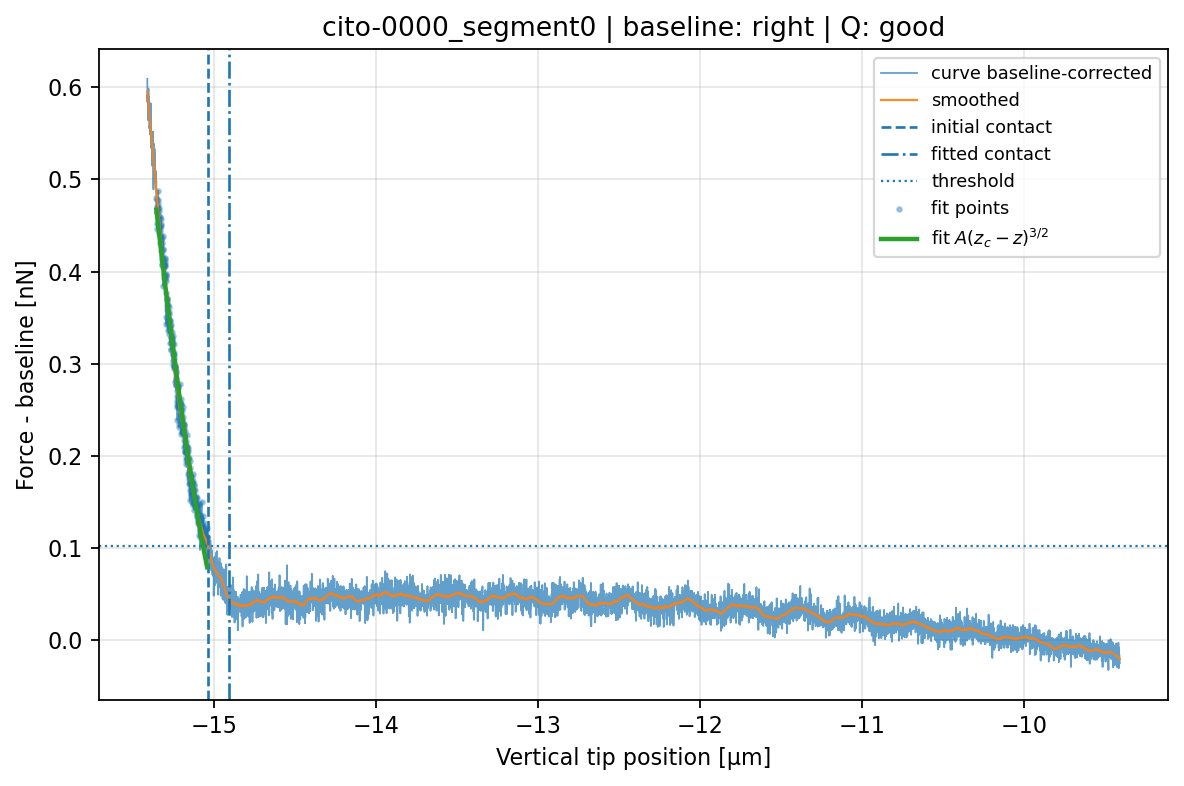

In [7]:

from IPython.display import Image, display

display(Image(filename=res["fit_plot"]))



## 5. Fit batch su tutte le curve segmento 0

Questa cella può richiedere un po' di tempo. Produce:

```text
afm_output/fit_hertz_like/fit_results_segment0.csv
afm_output/fit_hertz_like/plots/*.png
```


In [8]:

results = []
failures = []

for i, csv_path in enumerate(seg0_csv, start=1):
    try:
        r = fit_hertz_like_curve(csv_path, make_plot=True)
        results.append(r)
    except Exception as e:
        failures.append({"csv_file": csv_path.name, "csv_path": str(csv_path), "fit_status": "failed", "error": str(e)})

    if i % 25 == 0 or i == len(seg0_csv):
        print(f"Processed {i}/{len(seg0_csv)}")

fit_results = pd.DataFrame(results + failures)
fit_results.to_csv(FIT_TABLE_PATH, index=False)

print("Fit ok:", len(results))
print("Fit failed:", len(failures))
print("Saved:", FIT_TABLE_PATH)

display(fit_results.head())


Processed 25/257
Processed 50/257
Processed 75/257
Processed 100/257
Processed 125/257
Processed 150/257
Processed 175/257
Processed 200/257
Processed 225/257
Processed 250/257
Processed 257/257
Fit ok: 257
Fit failed: 0
Saved: /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/fit_results_segment0.csv


,csv_file,csv_path,n_points,baseline_side,approach_direction,z_min_um,z_max_um,baseline_nN,baseline_noise_pN,contact_idx_initial,...,fit_force_low_nN,fit_force_high_nN,n_fit_points,A_nN_per_um_3over2,A_err_nN_per_um_3over2,fit_rmse_nN,fit_r2,fit_status,fit_quality_flag,fit_plot
0,cito-0000_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000,right,right_to_left,-15.409008,-9.411679,0.021959,12.778282,377,...,0.102226,0.487329,309,1.543671,0.018387,0.014851,0.982332,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
1,cito-0005_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,4700,right,right_to_left,-15.592912,-10.896858,0.034312,11.057050,472,...,0.088456,0.565591,383,1.654191,0.022548,0.024005,0.972940,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
2,cito-0006_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,5413,right,right_to_left,-15.767386,-10.357957,0.025869,10.533824,690,...,0.084271,0.456365,582,0.479768,0.004750,0.015104,0.976856,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
3,cito-0007_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000,right,right_to_left,-15.621139,-9.624797,0.102729,10.392184,526,...,0.083137,0.443072,446,0.729394,0.007207,0.012953,0.982288,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
4,cito-0008_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000,right,right_to_left,-15.645828,-9.651365,0.046276,11.176091,599,...,0.089409,0.613925,526,0.962277,0.012783,0.027405,0.963774,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...



## 6. Recupera gruppo sperimentale dal nome/percorso

Se il CSV contiene già `meta_group`, usiamo quello. Altrimenti cerchiamo di ricostruirlo dal nome del file/percorso.


In [9]:

def infer_group_from_csv(csv_path):
    try:
        df0 = pd.read_csv(csv_path, nrows=1)
        if "meta_group" in df0.columns:
            return str(df0["meta_group"].iloc[0])
    except Exception:
        pass

    s = str(csv_path)
    known_groups = summary["group"].dropna().unique() if "group" in summary.columns else []
    for g in known_groups:
        if str(g) in s:
            return str(g)
    return "unknown"

fit_results["group"] = fit_results["csv_path"].apply(infer_group_from_csv)
fit_results.to_csv(FIT_TABLE_PATH, index=False)

display(fit_results[["csv_file", "group", "fit_status", "A_nN_per_um_3over2", "A_err_nN_per_um_3over2", "fit_r2", "fit_rmse_nN"]].head())


,csv_file,group,fit_status,A_nN_per_um_3over2,A_err_nN_per_um_3over2,fit_r2,fit_rmse_nN
0,cito-0000_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,1.543671,0.018387,0.982332,0.014851
1,cito-0005_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,1.654191,0.022548,0.972940,0.024005
2,cito-0006_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.479768,0.004750,0.976856,0.015104
3,cito-0007_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.729394,0.007207,0.982288,0.012953
4,cito-0008_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.962277,0.012783,0.963774,0.027405



## 7. Primo controllo dei risultati

Questi grafici non sono ancora conclusivi: servono a capire se il fit sta lavorando in modo ragionevole e se alcuni gruppi hanno distribuzioni molto diverse del parametro efficace \(A\).


Fit validi: 257


,A_nN_per_um_3over2,A_err_nN_per_um_3over2,fit_r2,fit_rmse_nN,baseline_noise_pN
count,257.000000,257.000000,257.000000,257.000000,257.000000
mean,0.788468,0.007679,0.982221,0.014817,9.312483
std,0.583801,0.007788,0.014619,0.005422,1.992207
min,0.218468,0.001020,0.844239,0.009274,6.551369
25%,0.424095,0.002620,0.980445,0.011710,7.872050
50%,0.618659,0.005106,0.986043,0.013318,8.898016
75%,0.989182,0.010442,0.989865,0.016357,10.128434
max,4.821835,0.057438,0.994782,0.061349,20.164667


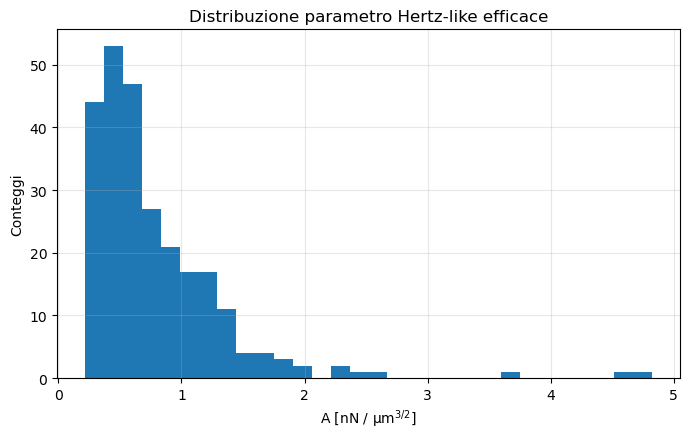

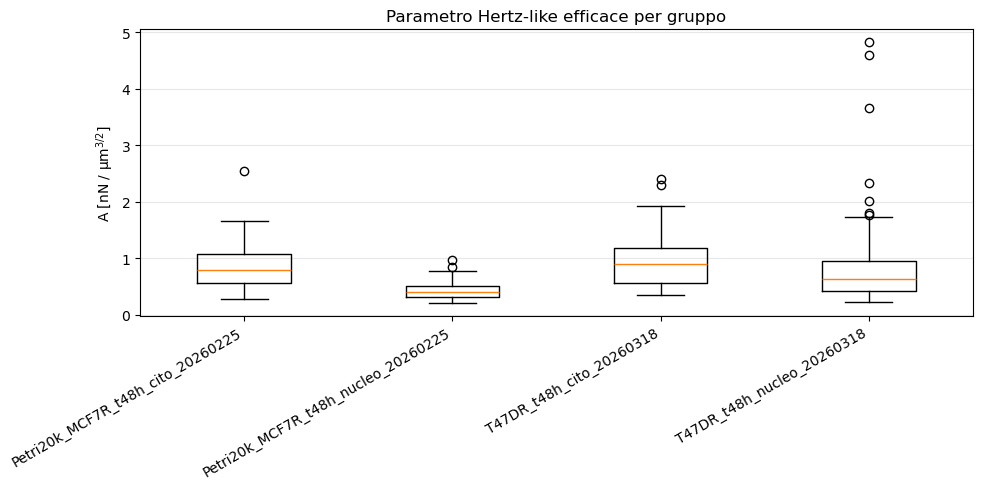

In [10]:

ok = fit_results[fit_results["fit_status"] == "ok"].copy()

print("Fit validi:", len(ok))
display(ok[["A_nN_per_um_3over2", "A_err_nN_per_um_3over2", "fit_r2", "fit_rmse_nN", "baseline_noise_pN"]].describe())

plt.figure(figsize=(7, 4.5))
plt.hist(ok["A_nN_per_um_3over2"].replace([np.inf, -np.inf], np.nan).dropna(), bins=30)
plt.xlabel(r"A [nN / µm$^{3/2}$]")
plt.ylabel("Conteggi")
plt.title("Distribuzione parametro Hertz-like efficace")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIT_OUTPUT_DIR / "hist_A_hertz_like.png", dpi=160, bbox_inches="tight")
plt.show()

groups = [g for g in ok["group"].dropna().unique()]
data = [ok.loc[ok["group"] == g, "A_nN_per_um_3over2"].dropna().values for g in groups]

plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=groups, showfliers=True)
plt.xticks(rotation=30, ha="right")
plt.ylabel(r"A [nN / µm$^{3/2}$]")
plt.title("Parametro Hertz-like efficace per gruppo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIT_OUTPUT_DIR / "boxplot_A_by_group.png", dpi=160, bbox_inches="tight")
plt.show()



## 8. Curve con fit sospetto

Guardiamo le curve con fit peggiore. Tipicamente sono quelle con \(R^2\) basso, RMSE alto o parametro \(A\) fuori scala.


In [11]:

bad_fit = ok.sort_values(["fit_r2", "fit_rmse_nN"], ascending=[True, False]).head(20)
display(bad_fit[["csv_file", "group", "A_nN_per_um_3over2", "fit_r2", "fit_rmse_nN", "baseline_noise_pN", "fit_plot"]])


,csv_file,group,A_nN_per_um_3over2,fit_r2,fit_rmse_nN,baseline_noise_pN,fit_plot
5,cito-0009_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.542173,0.844239,0.061349,14.405456,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
31,cito-0052_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.590698,0.893798,0.043722,11.695769,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
51,cito-0082_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.867490,0.920334,0.021839,10.950266,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
8,cito-0013_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.641539,0.934424,0.017244,18.457112,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
145,cito-0050_segment0.csv,T47DR_t48h_cito_20260318,0.958721,0.946921,0.022908,7.987532,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
50,cito-0081_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,1.308379,0.947120,0.036477,11.209897,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
53,cito-0085_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,1.306921,0.949318,0.026640,10.095567,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
19,cito-0032_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.926528,0.953933,0.024008,12.056559,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
134,cito-0034_segment0.csv,T47DR_t48h_cito_20260318,1.228982,0.954275,0.024007,8.213322,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
93,nucleo-0054_segment0.csv,Petri20k_MCF7R_t48h_nucleo_20260225,0.325353,0.955422,0.010927,12.301232,/Users/gmoretti/Work/AFM/Code_General/afm_outp...



## 9. Interpretazione provvisoria

Cose da controllare nei plot salvati:

- il contact point stimato cade dove inizia davvero la crescita della forza?
- il fit usa una regione sensata?
- il segno della forza è corretto?
- ci sono curve in cui l'algoritmo fitta il tratto sbagliato?
- l'ordinamento di `z` è coerente con l'approach?

Questa versione serve per individuare i problemi. La prossima iterazione migliorerà il contact point e la scelta automatica del fit range.
